# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

Name : Vaishnavi Goyal

SRN : PES2UG24CS571

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

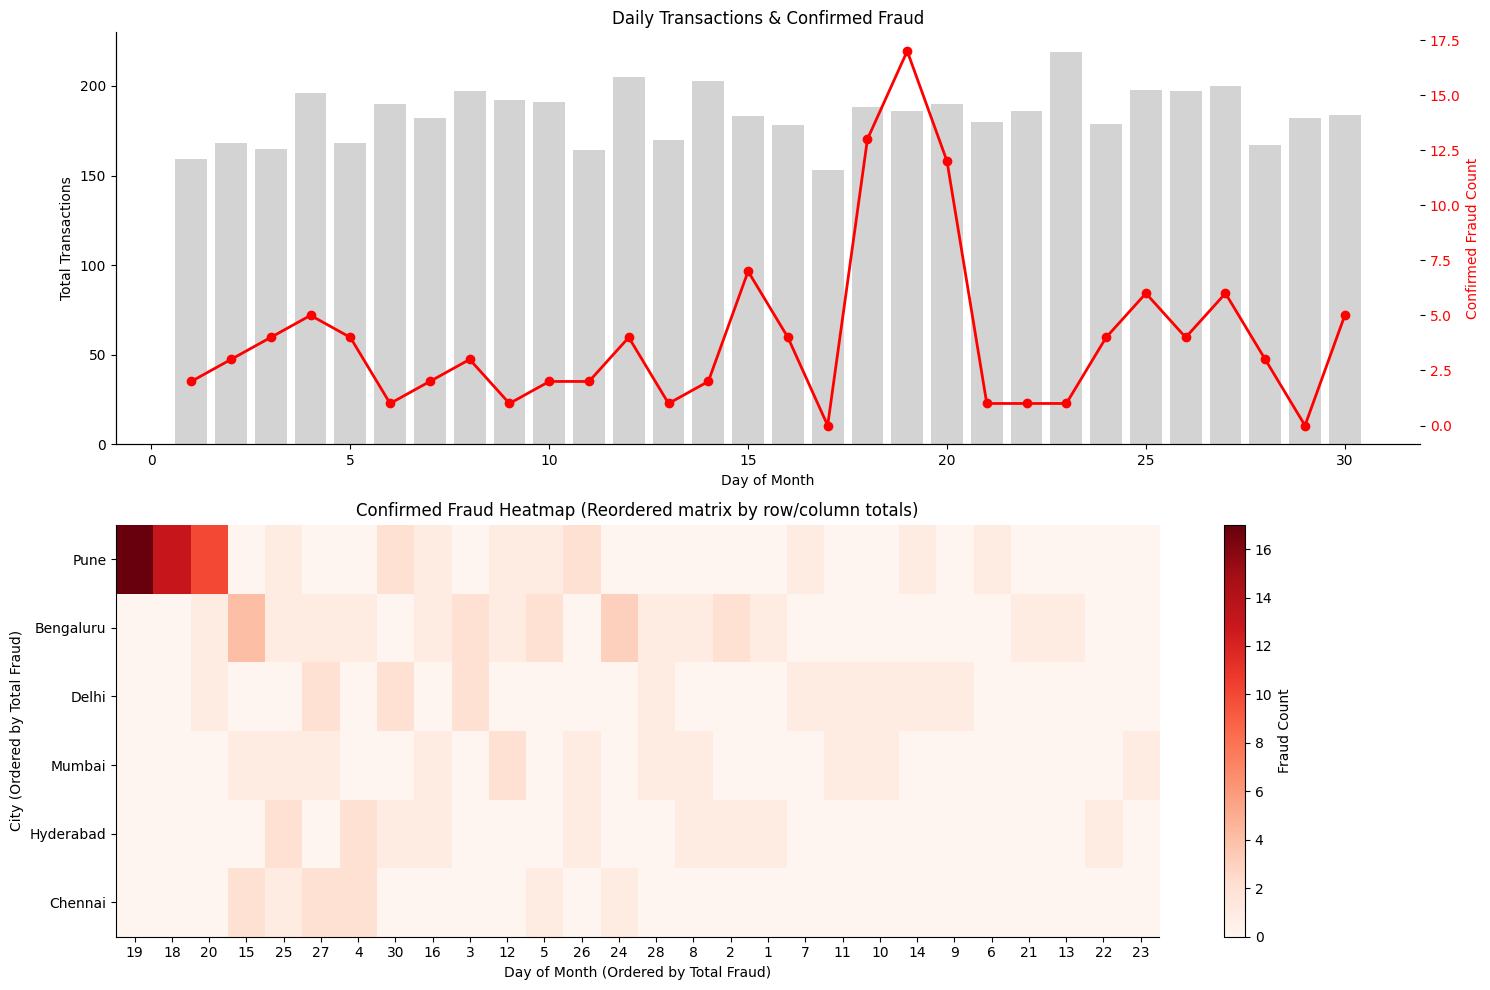

Top (City, Day) cells with most fraud:
City: Pune, Day: 19 -> 17 confirmed frauds
City: Pune, Day: 18 -> 13 confirmed frauds
City: Pune, Day: 20 -> 10 confirmed frauds
City: Bengaluru, Day: 15 -> 4 confirmed frauds
City: Bengaluru, Day: 24 -> 3 confirmed frauds


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# TODO 1: Plot daily transaction counts with daily confirmed fraud on a second axis.
# Daily tx counts
daily_tx = tx.groupby("day").size().reset_index(name="tx_count")
daily_fraud = tx[tx.is_fraud == 1].groupby("day").size().reset_index(name="fraud_count")
daily_data = pd.merge(daily_tx, daily_fraud, on="day", how="left").fillna(0)

ax1 = axes[0]
ax1.bar(daily_data["day"], daily_data["tx_count"], color="lightgrey", label="Transaction Count")
ax1.set_xlabel("Day of Month")
ax1.set_ylabel("Total Transactions", color="black")
ax1.tick_params(axis="y", labelcolor="black")

ax2 = ax1.twinx()
ax2.plot(daily_data["day"], daily_data["fraud_count"], color="red", marker="o", linewidth=2, label="Confirmed Fraud")
ax2.set_ylabel("Confirmed Fraud Count", color="red")
ax2.tick_params(axis="y", labelcolor="red")
ax1.set_title("Daily Transactions & Confirmed Fraud")

# TODO 2: Build a city x day matrix of confirmed-fraud counts, reorder rows/cols by totals
fraud_tx = tx[tx.is_fraud == 1]
heat_df = fraud_tx.groupby(["city", "day"]).size().unstack(fill_value=0)

# Reorder by totals
row_totals = heat_df.sum(axis=1)
col_totals = heat_df.sum(axis=0)
heat_df = heat_df.loc[row_totals.sort_values(ascending=False).index]
heat_df = heat_df[col_totals.sort_values(ascending=False).index]

heat = heat_df.values
cities = heat_df.index.tolist()
days = heat_df.columns.tolist()

ax_heat = axes[1]
im = ax_heat.imshow(heat, cmap="Reds", aspect="auto")
ax_heat.set_xticks(range(len(days)))
ax_heat.set_xticklabels(days)
ax_heat.set_yticks(range(len(cities)))
ax_heat.set_yticklabels(cities)
ax_heat.set_xlabel("Day of Month (Ordered by Total Fraud)")
ax_heat.set_ylabel("City (Ordered by Total Fraud)")
ax_heat.set_title("Confirmed Fraud Heatmap (Reordered matrix by row/column totals)")
fig.colorbar(im, ax=ax_heat, label="Fraud Count")

plt.tight_layout()
plt.show()

# TODO 3: Print the (city, day) cells with the most fraud
flat_unstacked = heat_df.unstack()
top_fraud = flat_unstacked.sort_values(ascending=False).head(5)
print("Top (City, Day) cells with most fraud:")
for (day, city), val in top_fraud.items():
    if val > 0:
        print(f"City: {city}, Day: {day} -> {val:.0f} confirmed frauds")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview immediately revealed a massive, concentrated spike in fraudulent transactions localized within a single city (Pune) during a specific timeframe (Days 18 to 20). An alert list sorted purely by detector score would obscure this collective, spatiotemporal clustering pattern because it lists individual alerts sequentially rather than summarizing them. The lecture concept that describes how we found this is a **Reordered Matrix (or Matrix Reordering)**. By grouping and sorting the rows (cities) and columns (days) by their marginal totals, the sparse, scattered fraud data was clustered into a clear, dense visual region at the top-left of the heatmap, making the anomalous fraud ring instantly recognizable.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

/tmp/ipykernel_1440/3082674130.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(cat_all.index, rotation=45, ha="right")
/tmp/ipykernel_1440/3082674130.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(city_all.index, rotation=45, ha="right")


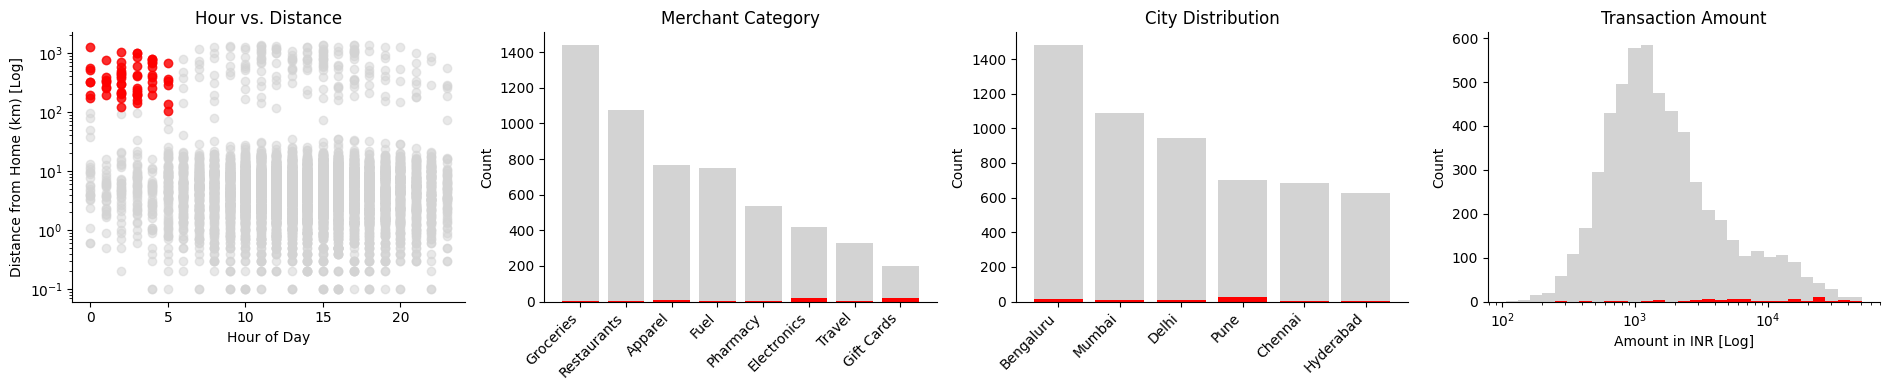

Number of transactions brushed: 61
Fraud rate inside brush: 86.89% vs. overall rate: 2.17%
Share of all fraud captured: 44.17%


In [4]:
# TODO 1: Define the brush: night-time (hour < 6) and distance_from_home_km > 100
brush = (tx["night"] == True) & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2: Four coordinated views (Grey background / Red highlighted brush)
# (a) hour vs. distance scatter (log y)
axes[0].scatter(tx["hour"], tx["distance_from_home_km"], color="lightgrey", alpha=0.5, label="All")
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"], color="red", alpha=0.8, label="Brushed")
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Distance from Home (km) [Log]")
axes[0].set_title("Hour vs. Distance")

# (b) merchant category counts
cat_all = tx["merchant_category"].value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_all.index, fill_value=0)
axes[1].bar(cat_all.index, cat_all.values, color="lightgrey", label="All")
axes[1].bar(cat_brush.index, cat_brush.values, color="red", label="Brushed")
axes[1].set_xticklabels(cat_all.index, rotation=45, ha="right")
axes[1].set_ylabel("Count")
axes[1].set_title("Merchant Category")

# (c) city counts
city_all = tx["city"].value_counts()
city_brush = tx.loc[brush, "city"].value_counts().reindex(city_all.index, fill_value=0)
axes[2].bar(city_all.index, city_all.values, color="lightgrey")
axes[2].bar(city_brush.index, city_brush.values, color="red")
axes[2].set_xticklabels(city_all.index, rotation=45, ha="right")
axes[2].set_ylabel("Count")
axes[2].set_title("City Distribution")

# (d) amount histogram (log10)
bins = np.logspace(np.log10(max(1, tx["amount_inr"].min())), np.log10(tx["amount_inr"].max()), 30)
axes[3].hist(tx["amount_inr"], bins=bins, color="lightgrey", label="All")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=bins, color="red", label="Brushed")
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount in INR [Log]")
axes[3].set_ylabel("Count")
axes[3].set_title("Transaction Amount")

plt.tight_layout()
plt.show()

# TODO 3: Print stats
num_brushed = brush.sum()
total_tx = len(tx)

fraud_inside_brush = tx.loc[brush, "is_fraud"].sum()
total_fraud = tx["is_fraud"].sum()

rate_inside = fraud_inside_brush / num_brushed if num_brushed > 0 else 0
rate_overall = total_fraud / total_tx
share_captured = fraud_inside_brush / total_fraud

print(f"Number of transactions brushed: {num_brushed}")
print(f"Fraud rate inside brush: {rate_inside*100:.2f}% vs. overall rate: {rate_overall*100:.2f}%")
print(f"Share of all fraud captured: {share_captured*100:.2f}%")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush has an exceptionally high fraud rate of **86.89%** (53 out of 61 brushed transactions are confirmed fraud), and it captures **44.17%** (53 out of 120) of all fraud transactions. This tells the investigators that while "night-time, far-from-home" transactions are extremely high risk and should indeed be flagged, relying on this rule *alone* is still highly insufficient since it misses 55.83% of the fraud occurring in the system.

The **City Distribution** linked view hints at where the rest of the fraud is. It shows that Pune has a disproportionately high transaction count inside the brush and is heavily represented in overall fraud, suggesting that Pune itself is the main epicenter of fraud (possibly containing a highly localized fraud ring that doesn't necessarily trigger the "far-from-home" condition for local cards/customers).

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [5]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure time over 5 runs
import time
runs = []
for _ in range(5):
    t0 = time.perf_counter()
    res = big[(big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)]
    t1 = time.perf_counter()
    runs.append(t1 - t0)

best_s = min(runs)

# TODO 2: Compute stats
per_item_us = (best_s * 1_000_000) / len(big)
max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate 50M
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0.0, (1 - (0.1 / t_50m)) * 100) if t_50m > 0.1 else 0.0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 13.9 ms -> 0.0139 us/row -> max 7,216,565 rows in 0.1 s
50M rows -> 0.69 s; must skip 85.6% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
One prominent **reduce** technique from the lecture is **Aggregation (or Binning / Downsampling)**. By pre-aggregating the 50 million transactions into multidimensional bins (e.g., using a Datashader-like approach or a binned data-cube structure where counts are pre-computed for ranges of values), the interface only needs to query and render the binned summary statistics instead of individual records.

By using this technique, the analyst would lose **individual-level detail (details-on-demand)**. They would no longer be able to hover over or select a specific transaction to see its unique attributes (like exact transaction ID, category, or customer ID) without triggering a separate, slower query to retrieve details for that specific bin.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

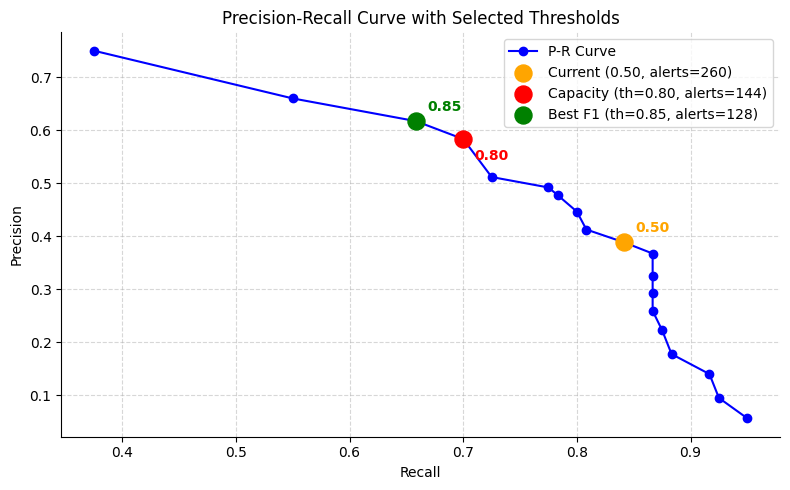

RECOMMENDATION: Move threshold to 0.80 (alerts: 144, precision: 58.3%, recall: 70.0%) to stay strictly within the team's limit of 150 monthly reviews.


In [6]:
rows = []
# TODO 1: Compute metrics for thresholds 0.05, 0.10, ..., 0.95
for th in np.arange(0.05, 1.0, 0.05):
    flagged = tx["detector_score"] >= th
    alerts = flagged.sum()
    tp = ((flagged == True) & (tx["is_fraud"] == 1)).sum()
    fp = ((flagged == True) & (tx["is_fraud"] == 0)).sum()
    fn = ((flagged == False) & (tx["is_fraud"] == 1)).sum()

    precision = tp / alerts if alerts > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    rows.append({
        "threshold": th,
        "alerts": alerts,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Find capacity-constrained choice (alerts <= 150, max recall) and best-F1 choice
under_capacity = pr[pr["alerts"] <= 150]
if not under_capacity.empty:
    # sorted by recall (descending) and then threshold (descending)
    capacity_choice = under_capacity.sort_values(by=["recall", "threshold"], ascending=[False, False]).iloc[0]
else:
    capacity_choice = pr.loc[pr["alerts"].idxmin()]

best_f1 = pr.loc[pr["f1"].idxmax()]
current_idx = np.abs(pr["threshold"] - 0.50).idxmin()
current_choice = pr.iloc[current_idx]

# TODO 3: Plot the precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], "b-o", label="P-R Curve")

# Mark current choice
ax.scatter(current_choice["recall"], current_choice["precision"], color="orange", s=150, zorder=5, label=f"Current (0.50, alerts={current_choice['alerts']:.0f})")
ax.text(current_choice["recall"] + 0.01, current_choice["precision"] + 0.02, "0.50", color="orange", weight="bold")

# Mark capacity-constrained choice
ax.scatter(capacity_choice["recall"], capacity_choice["precision"], color="red", s=150, zorder=5, label=f"Capacity (th={capacity_choice['threshold']:.2f}, alerts={capacity_choice['alerts']:.0f})")
ax.text(capacity_choice["recall"] + 0.01, capacity_choice["precision"] - 0.04, f"{capacity_choice['threshold']:.2f}", color="red", weight="bold")

# Mark best-F1 choice
ax.scatter(best_f1["recall"], best_f1["precision"], color="green", s=150, zorder=5, label=f"Best F1 (th={best_f1['threshold']:.2f}, alerts={best_f1['alerts']:.0f})")
ax.text(best_f1["recall"] + 0.01, best_f1["precision"] + 0.02, f"{best_f1['threshold']:.2f}", color="green", weight="bold")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve with Selected Thresholds")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# TODO 4: Print recommendation
print(f"RECOMMENDATION: Move threshold to {capacity_choice['threshold']:.2f} (alerts: {capacity_choice['alerts']:.0f}, precision: {capacity_choice['precision']*100:.1f}%, recall: {capacity_choice['recall']*100:.1f}%) to stay strictly within the team's limit of 150 monthly reviews.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops must make this call. A mathematical model can only calculate static metrics like the F1-score based on historical distributions, but it has no awareness of real-world operational constraints, such as hiring budgets, queue backlogs, or the financial costs of a missed fraud (false negative) versus an unnecessary investigation (false positive).

Visual analytics insists on keeping a **human-in-the-loop** because decision-making requires domain expertise, contextual judgment, and value-based trade-offs that cannot be fully automated. By presenting these trade-offs visually (like a precision-recall curve linked to investigator capacity), we empower the human decision-maker to steer parameters, understand the consequences (e.g., how much extra fraud will be missed to meet the 150-alert budget), and adjust strategies based on evolving operational realities.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:
# TODO 1: Interactive scatter of flagged transactions with detector_score >= 0.3
flagged_df = tx[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged_df,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    title="Flagged Transactions (Detector Score >= 0.3)",
    labels={"amount_inr": "Amount in INR", "timestamp": "Time of Transaction"}
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# TODO 2: Interactive sunburst: city -> merchant category
sun_df = tx.groupby(["city", "merchant_category"]).agg(
    count=("txn_id", "size"),
    fraud_rate=("is_fraud", "mean")
).reset_index()

fig_sun = px.sunburst(
    sun_df,
    path=["city", "merchant_category"],
    values="count",
    color="fraud_rate",
    color_continuous_scale="Reds",
    title="Hierarchical View of Transactions by City & Category (Sized by Count, Colored by Fraud Rate)"
)
fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips are highly interactive but require the investigator to hover over each data point individually (an action known as "detail-on-demand" without an overview). For 400 flagged cases, this becomes tedious, physically exhausting, and frustrating because it relies on the user's short-term memory to assemble a mental picture of the macro-level patterns, leading to high cognitive load.

The **Reordered Matrix Heatmap** (from Task 1) and the **Coordinated Linked Views/Bar Charts** (from Task 2) fix this. By summarizing the distribution of all cases across categories and cities simultaneously, these views instantly show the macro clusters, allowing the investigator to isolate the exact areas of interest before diving into individual tooltips.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

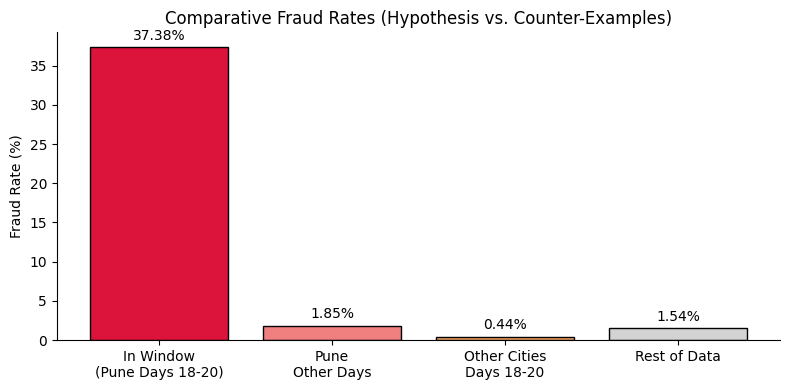

--- HYPOTHESIS TEST VERDICT ---
In-Window (Pune Days 18-20) Fraud Rate: 37.38% (40/107)
Out-of-Window Fraud Rate: 1.48% (80/5413)
Chi-square p-value: 1.065e-136
Counter-Example A (Pune, other days) Fraud Rate: 1.85%
Counter-Example B (Other cities, days 18-20) Fraud Rate: 0.44%
Rest of Data Fraud Rate: 1.54%
VERDICT: PROVED. The localized spike in Pune during Days 18-20 is highly statistically significant and represents an isolated, coordinated fraud ring outbreak.


In [8]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx["city"] == "Pune") & (tx["day"].isin([18, 19, 20]))

# TODO 2: Compute rates and chi-square p-value
total_in = in_window.sum()
tp_in = tx.loc[in_window, "is_fraud"].sum()
rate_in = tp_in / total_in if total_in > 0 else 0

total_out = (~in_window).sum()
tp_out = tx.loc[~in_window, "is_fraud"].sum()
rate_out = tp_out / total_out if total_out > 0 else 0

contingency_table = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

# TODO 3: Counter-example searches
# (a) same city on other days
mask_city_other_days = (tx["city"] == "Pune") & (~tx["day"].isin([18, 19, 20]))
total_city_other = mask_city_other_days.sum()
rate_city_other = tx.loc[mask_city_other_days, "is_fraud"].sum() / total_city_other if total_city_other > 0 else 0

# (b) other cities on same days
mask_other_cities_days = (tx["city"] != "Pune") & (tx["day"].isin([18, 19, 20]))
total_other_cities = mask_other_cities_days.sum()
rate_other_cities = tx.loc[mask_other_cities_days, "is_fraud"].sum() / total_other_cities if total_other_cities > 0 else 0

# (c) rest of the data
mask_rest = (tx["city"] != "Pune") & (~tx["day"].isin([18, 19, 20]))
total_rest = mask_rest.sum()
rate_rest = tx.loc[mask_rest, "is_fraud"].sum() / total_rest if total_rest > 0 else 0

# TODO 4: Visual confirmation
groups = ["In Window\n(Pune Days 18-20)", "Pune\nOther Days", "Other Cities\nDays 18-20", "Rest of Data"]
rates = [rate_in * 100, rate_city_other * 100, rate_other_cities * 100, rate_rest * 100]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(groups, rates, color=["crimson", "lightcoral", "sandybrown", "lightgrey"], edgecolor="black")
ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Comparative Fraud Rates (Hypothesis vs. Counter-Examples)")
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.2f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center", va="bottom")

plt.tight_layout()
plt.show()

# TODO 5: Print verdict
print(f"--- HYPOTHESIS TEST VERDICT ---")
print(f"In-Window (Pune Days 18-20) Fraud Rate: {rate_in*100:.2f}% ({tp_in}/{total_in})")
print(f"Out-of-Window Fraud Rate: {rate_out*100:.2f}% ({tp_out}/{total_out})")
print(f"Chi-square p-value: {p_val:.3e}")
print(f"Counter-Example A (Pune, other days) Fraud Rate: {rate_city_other*100:.2f}%")
print(f"Counter-Example B (Other cities, days 18-20) Fraud Rate: {rate_other_cities*100:.2f}%")
print(f"Rest of Data Fraud Rate: {rate_rest*100:.2f}%")
if p_val < 0.05 and rate_in > (rate_city_other * 5):
    print("VERDICT: PROVED. The localized spike in Pune during Days 18-20 is highly statistically significant and represents an isolated, coordinated fraud ring outbreak.")
else:
    print("VERDICT: KILLED. The localized spike cannot be statistically distinguished from background patterns or general seasonal fluctuations.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_
**Counter-Example Search B (Other cities on the same days, Days 18-20)** would have killed the hypothesis if it had yielded a fraud rate similar to or higher than Pune's in-window rate.

If other cities also experienced a massive spike in fraud during Days 18-20, it would have supported the alternative explanation of a **platform-wide systemic event**—such as a nationwide shopping holiday campaign (e.g., Great Indian Festival Sale), a successful global phishing exploit, or a core credential leak that impacted all cities simultaneously—rather than a highly localized offline physical "fraud ring" operating specifically in Pune.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_
Last month, we registered 5,520 transactions with 120 confirmed cases of fraud, including a highly concentrated spatiotemporal outbreak of 40 confirmed frauds in Pune specifically during Days 18–20. To prevent our team from drowning in alerts, I recommend shifting our detector threshold from 0.50 to 0.80. This capacity-constrained threshold keeps monthly reviews strictly under our limit at 144 alerts while maximizing our recall at 70.0% and improving precision to 58.3%, demonstrating the value of a human-in-the-loop to steer parameters according to operational reality. For our investigators, we should first build the Coordinated Linked Views dashboard because cross-view brushing allows them to immediately see how specific subsets of suspicious activities distribute across dimensions (like city, category, and amounts) in under 0.1 seconds, giving them a fast macro-to-micro workflow. Finally, we must establish a systematic **Feedback Loop** where the verified outcomes of the investigators' manual reviews are fed back into the model as new training labels to continuously refine and improve next month's detector accuracy.